# Esercizi da soli, svolti · Rischio, rendimento e frontiera efficiente

*Finanza Aziendale e Finanziamenti d'Impresa · A.A. 2026/27 · Esercitazione 4*

Un cliente ha 10.000 euro e vuole investirli in azioni italiane. Gli piacciono **Enel** («è tranquilla») e **Leonardo** («negli ultimi anni è salita tantissimo») e ti chiede: metto tutto su una delle due, o divido? E se aggiungessi **Terna** e **Stellantis**?

`ftsemib.csv` è lo stesso file visto insieme: i prezzi di fine mese, da novembre 2016 a ottobre 2026, di nove titoli del FTSE MIB (`TERNA`, `ENEL`, `GENERALI`, `ENI`, `FERRARI`, `INTESA`, `UNICREDIT`, `LEONARDO`, `STELLANTIS`) e dell'indice (`FTSEMIB`).

Gli esercizi seguono gli stessi passi fatti insieme su ENI e Ferrari. **Prima di scrivere codice, leggi la domanda** e completa la riga **Cosa mi chiede?**:
- i **titoli**: su quali colonne lavoro;
- la **misura**: rendimento, rischio, correlazione, pesi;
- il **comando**: una media, una deviazione standard, un grafico, una nuova colonna.

> **Per salvare il tuo lavoro scarica il notebook:** File → Scarica → Scarica .ipynb. Il file scaricato è tuo: per riaprirlo, su Colab File → Carica notebook, e da lì Salva funziona normalmente. Se hai aperto il notebook dal sito con *Apri in Colab*, non usare Salva: Colab proverebbe a salvarlo su GitHub.

In [1]:
import polars as pl
from plotnine import *
import random

In [2]:
prezzi = pl.read_csv("https://www.vincnardelli.com/msd/dati/ftsemib.csv", try_parse_dates=True) #try_parse_dates legge la colonna data come una data
prezzi.head()

data,TERNA,ENEL,GENERALI,ENI,FERRARI,INTESA,UNICREDIT,LEONARDO,STELLANTIS,FTSEMIB
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-11-01,2.6773,2.2345,6.8803,7.1134,47.8737,1.0306,7.1043,10.8254,3.6003,16930.0
2016-12-01,2.8474,2.4536,8.1502,8.3748,51.2072,1.1929,9.6059,11.7886,4.2794,19235.0
2017-01-01,2.655,2.3141,8.508,7.6927,53.4296,1.067,8.8399,10.5338,4.9881,18591.0
2017-02-01,2.8605,2.4267,7.8039,7.8605,56.9484,1.0818,8.8692,11.4616,5.1016,18913.0
2017-03-01,3.0423,2.6435,8.6004,8.3098,64.5878,1.2519,10.1312,11.7444,5.0621,20493.0


### 1.1 Com'è andato il prezzo di Leonardo in questi dieci anni? Fai il grafico del prezzo, poi calcola i rendimenti mensili di tutti i titoli e salvali in una tabella `rendimenti`. Quanto valgono oggi 1.000 euro investiti in Leonardo a novembre 2016?

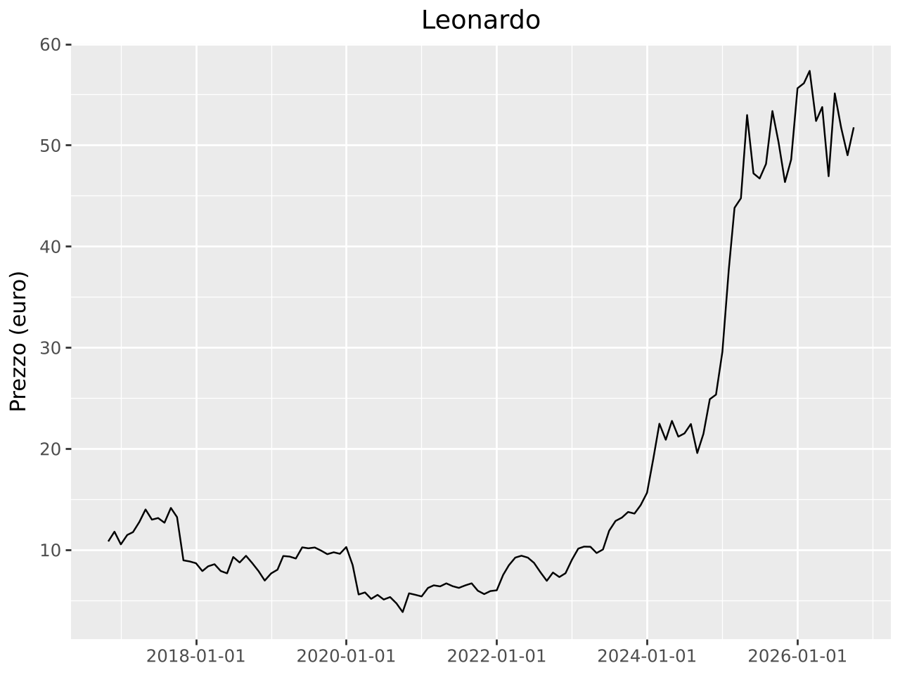

In [3]:
#da 10,83 euro a novembre 2016 a 51,76 a ottobre 2026, ma fino al 2022 non si era mosso
ggplot(prezzi, aes(x="data", y="LEONARDO"))+geom_line()+labs(x="", y="Prezzo (euro)", title="Leonardo")

In [4]:
#pct_change su tutte le colonne tranne la data, poi via la prima riga vuota
rendimenti = prezzi.with_columns(pl.exclude("data").pct_change()).drop_nulls()
rendimenti.head()

data,TERNA,ENEL,GENERALI,ENI,FERRARI,INTESA,UNICREDIT,LEONARDO,STELLANTIS,FTSEMIB
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-12-01,0.063534,0.098053,0.18457,0.177327,0.069631,0.157481,0.352125,0.088976,0.188623,0.136149
2017-01-01,-0.06757,-0.056855,0.043901,-0.081447,0.0434,-0.105541,-0.079743,-0.106442,0.165607,-0.033481
2017-02-01,0.077401,0.048658,-0.082757,0.021813,0.065859,0.013871,0.003315,0.088078,0.022754,0.01732
2017-03-01,0.063555,0.089339,0.102064,0.057159,0.134146,0.157238,0.14229,0.024674,-0.007743,0.08354
2017-04-01,-0.004273,-0.011311,-0.024836,-0.04402,-0.000514,0.050324,0.033905,0.085777,0.01367,0.00566


In [5]:
#1.000 euro sono diventati 4.781: quasi cinque volte tanto
rendimenti.select("data", valore=1000*(1+pl.col("LEONARDO")).cum_prod()).tail(1)

data,valore
date,f64
2026-10-01,4781.347571


### 1.2 Qual è il rendimento medio annuo di Enel? E quello di Leonardo? Qual è il rischio annuo (deviazione standard) dei due titoli? Il cliente ha ragione a dire che Enel è «tranquilla»?

In [6]:
rendimenti["ENEL"].mean()*12 #Enel rende il 16,8% l'anno

0.16803781556175212

In [7]:
rendimenti["LEONARDO"].mean()*12 #Leonardo il 23,3%

0.23267969092747803

In [8]:
rendimenti["ENEL"].std()*12**0.5 #rischio di Enel 21,7%

0.21674741721183

In [9]:
#rischio di Leonardo 38,8%: quasi il doppio di Enel
#il cliente ha ragione: Leonardo rende di più ma oscilla molto di più
rendimenti["LEONARDO"].std()*12**0.5

0.3881504018208849

### 1.3 Enel e Leonardo si muovono insieme? Fai un grafico a dispersione dei rendimenti dei due titoli e calcola la correlazione.

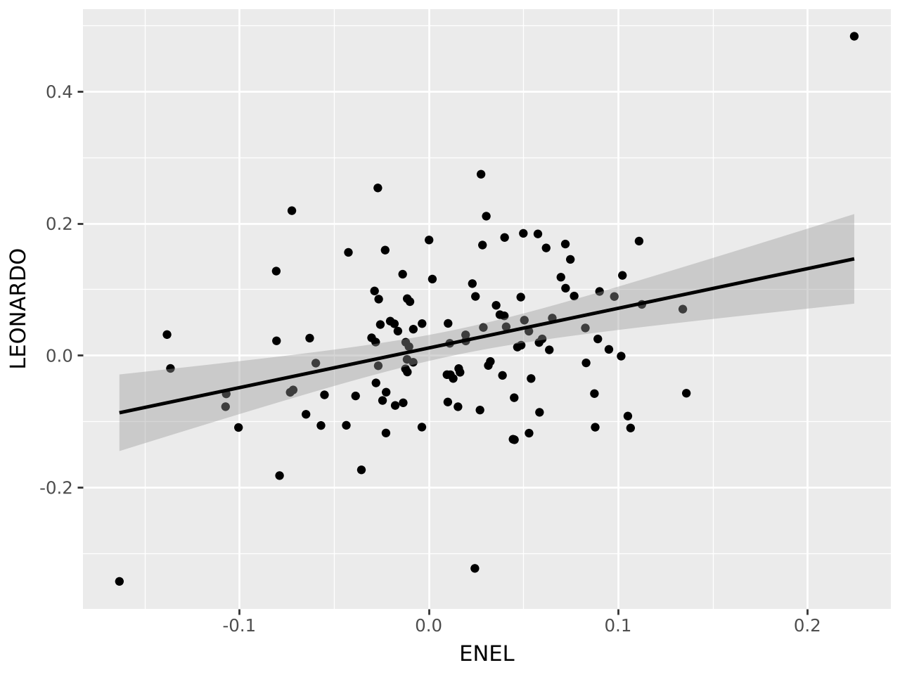

In [10]:
#la nuvola è larga, la retta sale
ggplot(rendimenti, aes(x="ENEL", y="LEONARDO"))+geom_point()+geom_smooth(method="lm")

In [11]:
#correlazione 0,34: positiva ma bassa, lontana dallo 0,86 delle due banche
rendimenti.select(pl.corr("ENEL", "LEONARDO"))

ENEL
f64
0.335636


### 1.4 Il cliente divide: 5.000 euro in Enel e 5.000 in Leonardo, e ribilancia ogni mese. Calcola rendimento e rischio annui del portafoglio. Il rischio è la media dei due rischi?

In [12]:
meta = rendimenti.with_columns(portafoglio=0.5*pl.col("ENEL")+0.5*pl.col("LEONARDO"))

In [13]:
#rendimento 20,0%: la media di 16,8% e 23,3%
meta["portafoglio"].mean()*12

0.20035875324461516

In [14]:
#rischio 25,2%: la media dei due rischi sarebbe 30,2%
#dividere toglie cinque punti di rischio rispetto alla media, senza togliere rendimento
meta["portafoglio"].std()*12**0.5

0.25204897053538

### 1.5 E se il cliente non ribilancia mai? Parti da 5.000 euro in Enel e 5.000 in Leonardo a novembre 2016 e lasciali crescere. Quanto pesa Leonardo a ottobre 2026? Fai il grafico del peso di Leonardo nel tempo.

In [15]:
#i due pezzi del portafoglio, ognuno per conto suo
senza = rendimenti.select("data", enel=5000*(1+pl.col("ENEL")).cum_prod(), leonardo=5000*(1+pl.col("LEONARDO")).cum_prod())
senza = senza.with_columns(peso_leonardo=pl.col("leonardo")/(pl.col("enel")+pl.col("leonardo")))
senza.tail(1) #a ottobre 2026 Leonardo pesa il 53%: 23.907 euro contro i 20.850 di Enel

data,enel,leonardo,peso_leonardo
date,f64,f64,f64
2026-10-01,20850.302081,23906.737857,0.534145


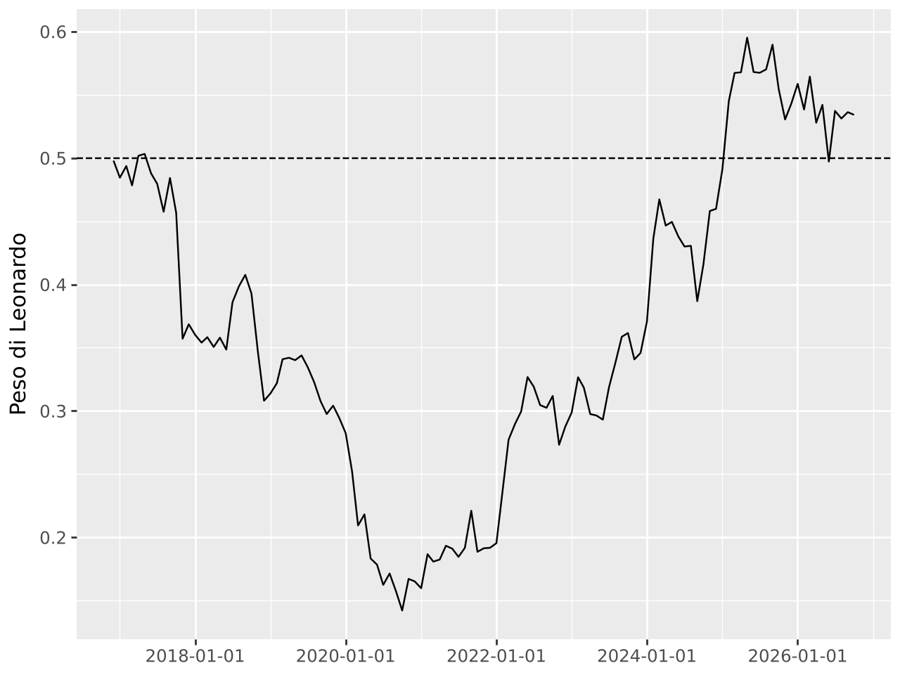

In [16]:
#Leonardo era sceso fino al 14% del portafoglio (ottobre 2020) ed è tornato sopra la metà solo nel 2025
#senza ribilanciare il portafoglio cambia da solo, e con lui il rischio
ggplot(senza, aes(x="data", y="peso_leonardo"))+geom_line()+geom_hline(yintercept=0.5, linetype="dashed")+labs(x="", y="Peso di Leonardo")

### 1.6 Quale divisione tra Enel e Leonardo ha il rischio più basso? Costruisci la curva di tutti i portafogli al variare della quota in Enel, disegnala e trova il minimo. Conviene mettere tutto su Enel?

In [17]:
m_1 = rendimenti["ENEL"].mean()*12
s_1 = rendimenti["ENEL"].std()*12**0.5
m_2 = rendimenti["LEONARDO"].mean()*12
s_2 = rendimenti["LEONARDO"].std()*12**0.5
rho = rendimenti.select(pl.corr("ENEL", "LEONARDO")).item()

In [18]:
#w è la quota in Enel
curva = pl.DataFrame({"w": range(0, 101)}).with_columns(w=pl.col("w")/100)
curva = curva.with_columns(
    rendimento=pl.col("w")*m_1+(1-pl.col("w"))*m_2,
    rischio=((pl.col("w")*s_1)**2+((1-pl.col("w"))*s_2)**2+2*pl.col("w")*(1-pl.col("w"))*rho*s_1*s_2).sqrt()
)

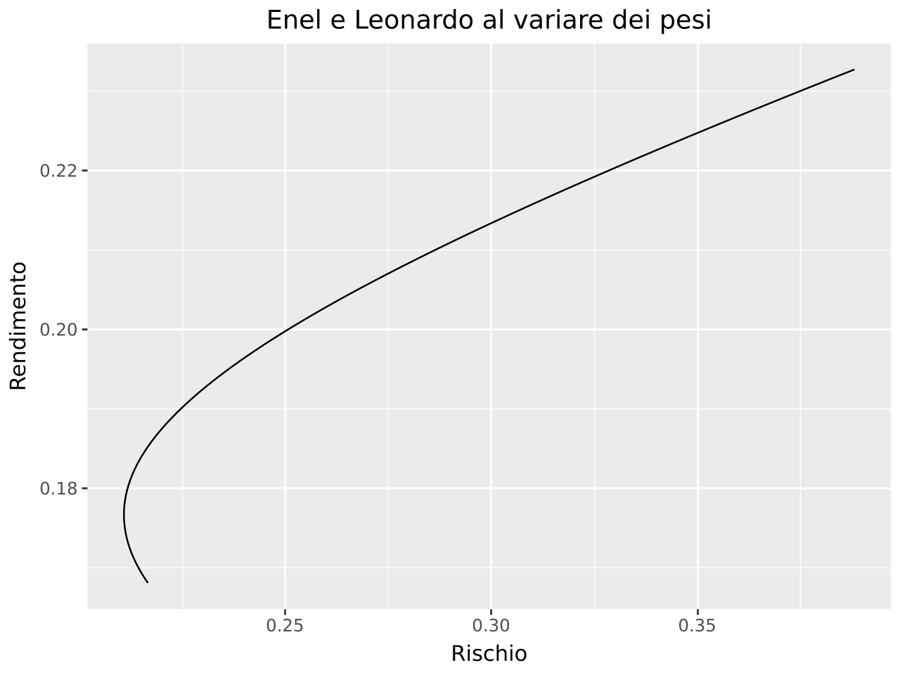

In [19]:
#in alto a destra tutto Leonardo, in basso tutto Enel
ggplot(curva, aes(x="rischio", y="rendimento"))+geom_path()+labs(x="Rischio", y="Rendimento", title="Enel e Leonardo al variare dei pesi")

In [20]:
#rischio minimo con 87% Enel e 13% Leonardo: rischio 21,1%, rendimento 17,6%
#rispetto a tutto Enel (21,7% e 16,8%): meno rischio e più rendimento. Tutto su Enel non conviene mai
curva.sort("rischio").head(1)

w,rendimento,rischio
f64,f64,f64
0.87,0.176441,0.210932


### 1.7 Il cliente aggiunge Terna e Stellantis. Costruisci 2.000 portafogli casuali con i quattro titoli (usa `random.seed(1)` e i titoli in quest'ordine: Enel, Leonardo, Terna, Stellantis), calcola rendimento e rischio annui di ognuno e disegna la nuvola.

In [21]:
lungo = rendimenti.unpivot(index="data", variable_name="titolo", value_name="rendimento")

In [22]:
random.seed(1)
nomi = ["ENEL", "LEONARDO", "TERNA", "STELLANTIS"]
righe = []
for p in range(2000):
    for t in nomi:
        righe.append({"portafoglio": p, "titolo": t, "numero": random.random()**3})
pesi = pl.DataFrame(righe).with_columns(peso=pl.col("numero")/pl.col("numero").sum().over("portafoglio"))

In [23]:
#peso x rendimento, sommato sui titoli per ogni mese, poi media e deviazione standard per portafoglio
contributi = pesi.join(lungo, on="titolo").with_columns(contributo=pl.col("peso")*pl.col("rendimento"))
mensili = contributi.group_by("portafoglio", "data").agg(rendimento=pl.col("contributo").sum())
portafogli = mensili.group_by("portafoglio").agg(rendimento=pl.col("rendimento").mean()*12, rischio=pl.col("rendimento").std()*12**0.5)

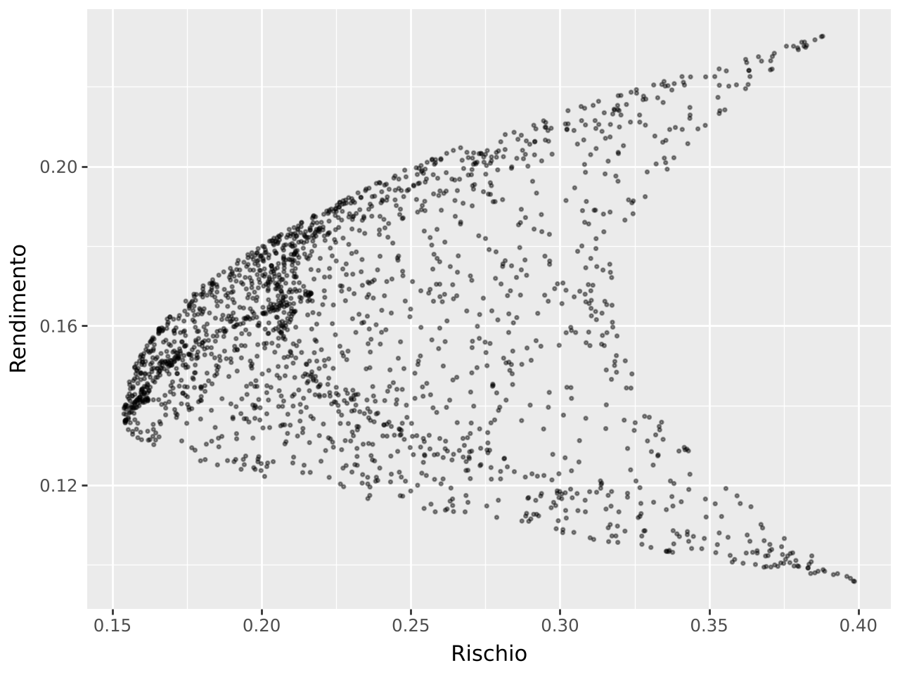

In [24]:
#la nuvola ha quattro punte: sono i portafogli quasi tutti su un solo titolo
ggplot(portafogli, aes(x="rischio", y="rendimento"))+geom_point(size=0.5, alpha=0.4)+labs(x="Rischio", y="Rendimento")

### 1.8 Quali sono i portafogli efficienti? Trova la frontiera, conta quanti sono e disegnala in rosso sopra la nuvola.

In [25]:
#in ordine di rischio, tengo chi rende più di tutti i precedenti
frontiera = portafogli.sort("rischio").with_columns(massimo=pl.col("rendimento").cum_max()).filter(pl.col("rendimento") == pl.col("massimo"))
frontiera.height #122 portafogli efficienti su 2.000

122

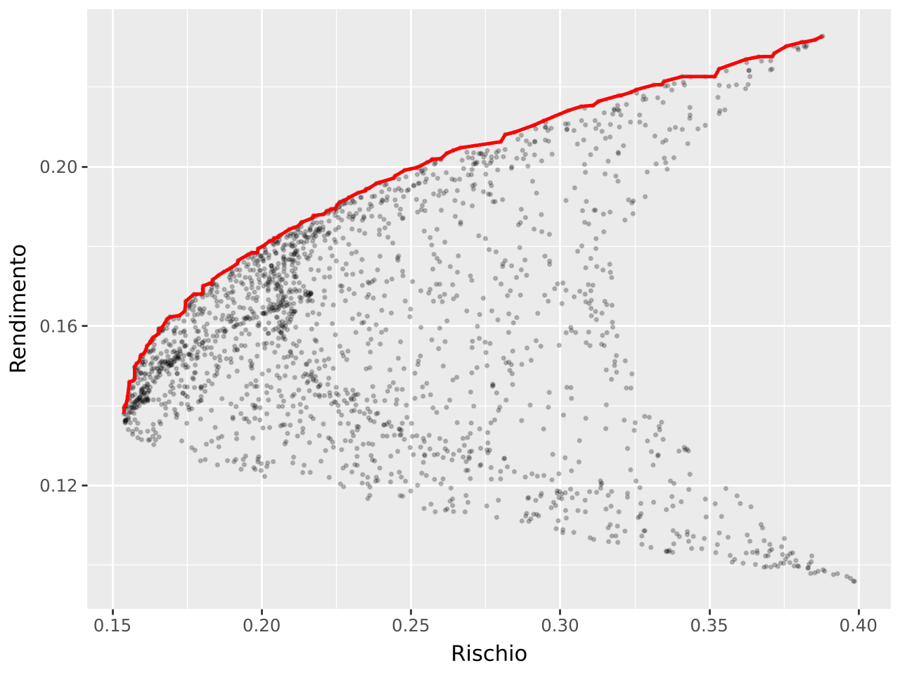

In [26]:
ggplot(portafogli, aes(x="rischio", y="rendimento"))+geom_point(size=0.5, alpha=0.2)+geom_line(data=frontiera, color="red", size=1)+labs(x="Rischio", y="Rendimento")

### 1.9 Qual è il portafoglio con l'indice di Sharpe più alto (tasso senza rischio 2,5%)? Con quali pesi? Quanto pesa Stellantis, e perché?

In [27]:
portafogli = portafogli.with_columns(sharpe=(pl.col("rendimento")-0.025)/pl.col("rischio"))

In [28]:
#il migliore: rendimento 16,2%, rischio 16,8%, Sharpe 0,81
portafogli.sort("sharpe", descending=True).head(1)

portafoglio,rendimento,rischio,sharpe
i64,f64,f64,f64
1481,0.161681,0.168356,0.811857


In [29]:
#portafoglio numero 1481: 71% Terna, 20% Leonardo, 9% Enel, Stellantis praticamente zero
#Stellantis ha il rischio più alto dei quattro (39,9%) e il rendimento più basso (9,6%): abbassa lo Sharpe
pesi.filter(pl.col("portafoglio") == 1481).select("titolo", "peso").sort("peso", descending=True)

titolo,peso
str,f64
"""TERNA""",0.709439
"""LEONARDO""",0.197363
"""ENEL""",0.093198
"""STELLANTIS""",1.0803e-9
